In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import PretrainedConfig, PreTrainedModel, GenerationMixin


class MiniMindConfig(PretrainedConfig):
    model_type = "minimind"
    def __init__(self, hidden_size=768, num_hidden_layers=8, use_moe=False, **kwargs):
        super().__init__(**kwargs)
        self.hidden_size = hidden_size
        self.num_hidden_layers = num_hidden_layers
        self.use_moe = use_moe
        self.dropout = kwargs.get("dropout", 0.0)
        self.vocab_size = kwargs.get("vocab_size", 6400)
        self.bos_token_id = kwargs.get("bos_token_id", 1)
        self.eos_token_id = kwargs.get("eos_token_id", 2)
        self.flash_attn = kwargs.get("flash_attn", True)
        self.num_attention_heads = kwargs.get("num_attention_heads", 8)
        self.num_key_value_heads = kwargs.get("num_key_value_heads", 4)
        self.head_dim = kwargs.get("head_dim", self.hidden_size // self.num_attention_heads)
        self.hidden_act = kwargs.get("hidden_act", 'silu')
        self.intermediate_size = kwargs.get("intermediate_size", math.ceil(hidden_size * math.pi / 64) * 64)
        self.max_position_embeddings = kwargs.get("max_position_embeddings", 32768)
        self.rms_norm_eps = kwargs.get("rms_norm_eps", 1e-6)
        self.rope_theta = kwargs.get("rope_theta", 1e6)
        self.tie_word_embeddings = kwargs.get("tie_word_embeddings", True)
        self.inference_rope_scaling = kwargs.get("inference_rope_scaling", False)
        self.rope_scaling = {
            "beta_fast": 32,
            "beta_slow": 1,
            "factor": 16,
            "original_max_position_embeddings": 2048,
            "attention_factor": 1.0,
            "type": "yarn"
        } if self.inference_rope_scaling else None
        ### MoE specific configs (ignored if use_moe = False)
        self.num_experts = kwargs.get("num_experts", 4)
        self.num_experts_per_tok = kwargs.get("num_experts_per_tok", 1)
        self.moe_intermediate_size = kwargs.get("moe_intermediate_size", self.intermediate_size)
        self.norm_topk_prob = kwargs.get("norm_topk_prob", True)
        self.router_aux_loss_coef = kwargs.get("router_aux_loss_coef", 5e-4)

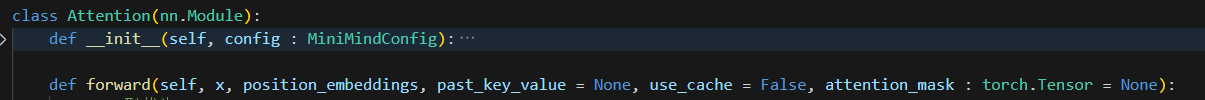


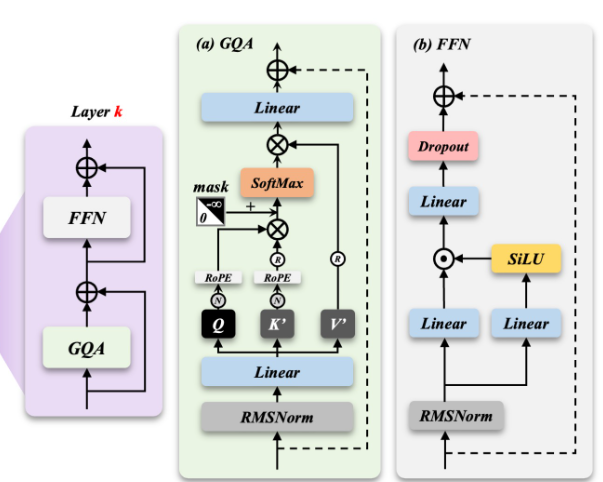
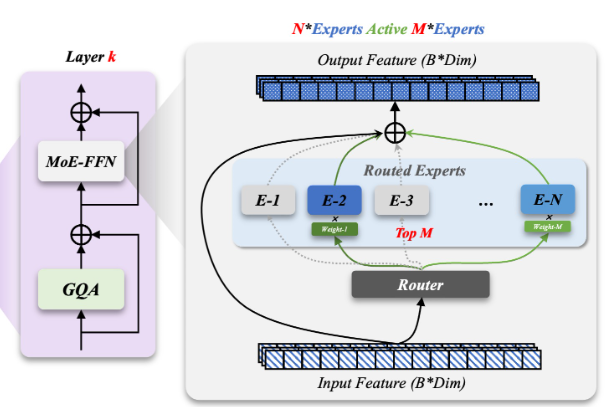

In [ ]:
class MiniMindBlock(nn.Module):
    def __init__(self, layer_id: int, config: MiniMindConfig):
        # 这里有何疑问: 这个 layer_id 是啥, 为什么在这个类里面都没用上
        # 由顶层 MiniMindModel 用 for l in range(num_hidden_layers) 传入，但块内部也没用到，属于预留参数（分层日志、逐层配置、hook、调试定位等)
        super().__init__()
        self.input_norm = RMSNorm(config.hidden_size, config.rms_norm_eps)
        self.post_attention_norm = RMSNorm(config.hidden_size, config.rms_norm_eps)
        self.attn = Attention(config)
        self.mlp = FeedForward(config) if not config.use_moe else MOEFeedForward(config)

    def forward(self, hidden_states, position_embeddings, past_key_value=None, use_cache=False, attention_mask=None):
        # hidden_states 形状 (batch_size, seq_len, hidden_size)
        residual = hidden_states
        # (batch_size, seq_len, hidden_size)
        hidden_states, present_key_value = self.attn(self.input_norm(hidden_states), position_embeddings, past_key_value, use_cache, attention_mask)
        hidden_states += residual # 残差连接

        # 经过 ffn / moe 层
        hidden_states = hidden_states + self.mlp(self.post_attention_norm(hidden_states))
        return hidden_states, present_key_value

In [ ]:
class MiniMindModel(nn.Module): # 等价于架构图中的 Large_Language_Model 部分 (负责把 token id 变成上下文相关的 hidden states；输出 logits 的 lm_head 在 MiniMindForCausalLM 里)
    def __init__(self, config: MiniMindConfig):
        super().__init__()
        self.config = config
        # vocab_size：词表的长度    num_hidden_layers：block循环几层
        self.vocab_size, self.num_hidden_layers = config.vocab_size, config.num_hidden_layers
        # 构建词表：[6400, 768]  有6400个词，每个词的向量维度是768
        self.embed_tokens = nn.Embedding(config.vocab_size, config.hidden_size)
        # 随机丢弃
        self.dropout = nn.Dropout(config.dropout)
        # hidden_size：768 词向量的维度     rms_norm_eps：可学习的缩放参数
        self.norm = RMSNorm(config.hidden_size, config.rms_norm_eps)
        # 生成num_hidden_layers（8）个MiniMindBlock
        self.layers = nn.ModuleList([MiniMindBlock(l, config) for l in range(config.num_hidden_layers)])
        # 位置编码生成并注册 cos, sin 表到 buffer 中
        freqs_cos, freqs_sin = precompute_freqs_cis(dim=config.head_dim, rope_base=config.rope_theta, end=config.max_position_embeddings, rope_scaling=config.rope_scaling)
        # persistent 表示 save() 的时候不会保存到 checkpoints 中, 不会出现在 state_dict() 里，也就不会被保存和加载。
        self.register_buffer("freqs_cos", freqs_cos, persistent=False)
        self.register_buffer("freqs_sin", freqs_sin, persistent=False)

    def forward(self, input_ids, attention_mask=None, past_key_values=None, use_cache=False, **kwargs):
        # input_ids 形状 (B, S) ,  attention_mask 形状 (B, S_total)，S_total = P + S；1 保留、0 屏蔽, 训练/prefill 时 S_total = S；decode 时 S = 1，S_total = P + 1
        # past_key_values 形状: List[Tuple(torch.Tensor, torch.Tensor)], 表示每一层存储的 KV 值, 其中 K 形状为 (B, P, num_kv_heads, head_dim) P 为之前存储的长度
        _, seq_length = input_ids.shape

        # 对 past_key_values 的检查
        if hasattr(past_key_values, 'layers'): past_key_values = None # 工程化兼容
        # 把 past_key_values 初始化一下方便后续直接调用
        past_key_values = past_key_values or [None] * self.num_hidden_layers

        # start_pos 找到当前输入的起始位置, 如果是 decode 阶段的话就会取出对应的开始位置, 
        # 比如此时第 0 层 KV Cache 存了(0...P - 1) P个 token的信息, 那么 start_pos == .shape[1] 就是 P, 表示下一个起始位置
        #past_key_values = [
        #   (k_layer0, v_layer0),     ← [0]         k_layer0 = (batch_size, P, num_key_value_heads, head_dim)
        #   (k_layer1, v_layer1),
        #   ...
        #   (k_layer7, v_layer7),
        #]
        # 对于训练 / prefill 阶段, 此时past_key_values 为 None, 就直接 0 开始即可
        start_pos = past_key_values[0][0].shape[1] if past_key_values[0] is not None else 0
        # 位置编码 (batch_size, seq_len, hidden_dim)
        hidden_states = self.dropout(self.embed_tokens(input_ids)) # 形状变为 (B, S, hidden_size) 把每个 token 转化为稠密向量

        # Recompute RoPE buffers lost during meta-device init (transformers>=5.x) meta-device 初始化兜底, 这个不用管    它是个保险丝，正常训练/推理根本不会走到
        if self.freqs_cos[0, 0] == 0:
            freqs_cos, freqs_sin = precompute_freqs_cis(dim=self.config.head_dim, rope_base=self.config.rope_theta, end=self.config.max_position_embeddings, rope_scaling=self.config.rope_scaling)
            self.freqs_cos, self.freqs_sin = freqs_cos.to(hidden_states.device), freqs_sin.to(hidden_states.device)

        # 取本次 S 个位置的 RoPE cos/sin，各自形状 (S, head_dim)
        # 注意：没有 batch 维 —— 同一位置对所有样本、所有层共享
        # 起点是 start_pos，保证 decode 时位置连续（P, P+1, ...）
        pos_embedding = (self.freqs_cos[start_pos:start_pos+seq_length], self.freqs_sin[start_pos:start_pos+seq_length])


        # 开始遍历每个 TransformerBlock 块并且更新 KV 缓存      收集每层返回的 KV cache，最后整体返回给上层。
        presents = [] # 形状为  List[Tuple(torch.Tensor, torch.Tensor)], 把每一层block 的 kv cache 保存成一个列表

        for layer, past_key_value in zip(self.layers, past_key_values):
            hidden_states, present = layer(hidden_states, pos_embedding, past_key_value, use_cache, attention_mask)
            presents.append(present)

        # 经过全部 block 之后进行 RMSNorm 归一化进入下游
        hidden_states = self.norm(hidden_states)

        # 计算 aux_loss(moe 的辅助损失函数), 这里设置 start=hidden_states.new_zeros(1).squeeze() 保证前面列表为空的时候输出也是一个 0 维张量, 不是 int0
        aux_loss = sum([layer.mlp.aux_loss for layer in self.layers if isinstance(layer.mlp, MOEFeedForward)], hidden_states.new_zeros(1).squeeze())

        return hidden_states, presents, aux_loss

In [ ]:
class MiniMindForCausalLM(PreTrainedModel, GenerationMixin):
    # 2026.11.02.17.38

    # 写在类体里的静态声明, 类属性
    config_class = MiniMindConfig
    _tied_weights_keys = {"lm_head.weight": "model.embed_tokens.weight"}

    def __init__(self, config: MiniMindConfig=None):
        self.config = config or MiniMindConfig()
        super().__init__(self.config)
        self.model = MiniMindModel(self.config) # backbone
        self.lm_head = nn.Linear(self.config.hidden_size, self.config.vocab_size, bias=False) # logits = hidden @ weight.T，输出 (B, S, V)
        # 这个就是把前面你使用词向量编码的参数矩阵和后面解码的参数矩阵要一样
        if self.config.tie_word_embeddings: self.lm_head.weight = self.model.embed_tokens.weight # 手动权重绑定
        self.post_init() # 做 HF 式初始化和元数据登记

    def forward(self, input_ids, attention_mask=None, past_key_values=None, use_cache=False, logits_to_keep=0, labels=None, **kwargs):
        # 这个 input_ids 形状为 (B, S)
        # labels 默认 (B, S)（配合 logits_to_keep = 0）；若 logits_to_keep = K > 0，必须是 (B, K)，否则 loss 形状不匹配；-100 表示忽略
        # attention_mask (B, S_total)，1 保留 / 0 屏蔽

        # hidden_state (B, S, H), 表示 model 输出的隐状态
        hidden_states, past_key_values, aux_loss = self.model(input_ids, attention_mask, past_key_values, use_cache, **kwargs)

        # 拿到要计算最后面 logits_to_keep 的 slice (如果 logits_to_keep 已经是显示规定了 slice 就直接使用)
        # 这个就是截断，不是使用所有的token去预测下一个token，而是使用最新的logits_to_keep的token去预测减小计算量
        slices = slice(-logits_to_keep, None) if isinstance(logits_to_keep, int) else logits_to_keep

        # 把对应 token 的行取出来并经过 self.lm_head 获取每个 token 对应的 logits, 形状 (B ,K, H) @ (H, V) -> (B, K, V)
        logits = self.lm_head(hidden_states[:, slices, :])

        loss = None
        if labels is not None:
            # 得到训练样本的 logits (B, logits_to_keep, V) 和真实对应的 labels (B, S), y 后移一位与 x 对应上 (在 logits_to_keep=0 时其实是 (B, S, V))
            x, y = logits[:, :-1, :].contiguous(), labels[:, 1:].contiguous()
            # 计算交叉熵, 这里要求 input 为二维张量, labels 为一维张量表示实际标签, 当 labels 里面有 -100 表示忽略这个 token
            loss = F.cross_entropy(x.view(-1, x.shape[-1]), y.view(-1), ignore_index=-100)

        return MoeCausalLMOutputWithPast(loss=loss, aux_loss=aux_loss, logits=logits, past_key_values=past_key_values, hidden_states=hidden_states)
        # 2026.11.02.18.19

    # 不构建 autograd 图，推理更快、更省显存
    # 产出的张量是 "inference tensor"，之后不能再参与需要梯度的计算
    @torch.inference_mode()
    def generate(self, inputs=None, attention_mask=None, max_new_tokens=8192, temperature=0.85, top_p=0.85, top_k=50,
                 eos_token_id=2, streamer=None, use_cache=True, num_return_sequences=1, do_sample=True, repetition_penalty=1.0, **kwargs):
        # prompt token ids，(B, P), num_return_sequences 表示 每个 prompt 返回几条, do_sample = False 退化到 greedy

        # 初始化状态
        #  兼容调用方式 + 防止参数冲突, 后续还会 forward 调用这个 **kwargs, 把输入复制 n 份，实现整个 batch 重复 n 次"排列
        input_ids = kwargs.pop("input_ids", inputs).repeat(num_return_sequences, 1)
        attention_mask = attention_mask.repeat(num_return_sequences, 1) if attention_mask is not None else None  # 把 mask 同步复制
        past_key_values = kwargs.pop("past_key_values", None) # 允许从已有 cache 继续生成（多轮对话 / 断点续写）
        finished = torch.zeros(input_ids.shape[0], dtype=torch.bool, device=input_ids.device) # 记录哪些行已经遇到 EOS, 形状为 (B * num_return_sequence(后面记为B1)), bool 型, 0表示结尾不是EOS

        if streamer: streamer.put(input_ids.cpu())
        for _ in range(max_new_tokens):
            # 第 0 层 k 的序列长度 = 历史长度 P
            # 第 1 轮（prefill）：past=None → past_len=0，喂整段 prompt,  之后每轮：past_len=P，只喂最后一个新 token
            past_len = past_key_values[0][0].shape[1] if past_key_values else 0
            # 只喂未缓存的后缀, 经过 forward 获取 logits
            outputs = self.forward(input_ids[:, past_len:], attention_mask, past_key_values, use_cache=use_cache, **kwargs) # decode 时 outputs.logits 形状 (B1, 1, V)
            # forward 时 mask 长度 = 历史 + 本次输入
            # forward 之后要把刚生成的新 token 也补进 mask，供下一轮使用
            # 每轮只补 1 个，因为这个循环每轮只生成 1 个 token
            attention_mask = torch.cat([attention_mask, attention_mask.new_ones(attention_mask.shape[0], 1)], dim=-1) if attention_mask is not None else None

            logits = outputs.logits[:, -1, :] / temperature # 取最后一个位置的 logits 并加温度 形状 (B1, V)

            # 重复惩罚
            if repetition_penalty != 1.0:  # 1.0 等于不启用
                for i in range(input_ids.shape[0]):  # 对 batch 里每一条序列分别处理
                    seen = torch.unique(input_ids[i])  # ① 这条序列里出现过的所有 token id（去重）
                    score = logits[i, seen]  # ② 取出这些 token 当前的 logit 值（高级索引 gather）
                    logits[i, seen] = torch.where(  # ④ 改完再写回
                        score > 0,  # ③ 正 logit → 除以 penalty
                        score / repetition_penalty,  # 负 logit → 乘以 penalty
                        score * repetition_penalty)

            # top-k
            if top_k > 0:
                # 这里 torch.topk(logits, topk) 形状为 (B1, topk), 然后[0] 取 values, [..., -1, None] 取最后一列 (threshold) 并升维成 (B1, 1) 进行广播
                # 把每一行值 < threshold 的变成 -inf
                logits[logits < torch.topk(logits, top_k)[0][..., -1, None]] = -float('inf')

            # top-p（nucleus）
            if top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(logits, descending=True) # 形状为 (B1, V), 从大到小排序
                # 对排序后的 logits 做 softmax，再累加，得到累计概率 cumsum
                # cumsum > top_p 的位置标为 True——这些是"超出 nucleus 的范围"
                mask = torch.cumsum(torch.softmax(sorted_logits, dim=-1), dim=-1) > top_p  # 形状为 (B1, V), bool 型, 按行计算
                # 右移一位：mask[j] = mask[j-1]，且 mask[0]=0
                # 目的是保留第一个让累计概率跨过 top_p 的 token, 越过阈值那个也保留
                mask[..., 1:], mask[..., 0] = mask[..., :-1].clone(), 0
                # mask.scatter(1, sorted_indices, mask)：把"排序后顺序"的 mask 映射回原词表顺序
                # sorted_indices[j] 是排序后第 j 个 token 在词表中的下标, scatter 把 mask[j] 写到 result[sorted_indices[j]]
                # 这里比较难理解, 可以看笔记里的例子
                logits[mask.scatter(1, sorted_indices, mask)] = -float('inf')

            # 采样
            next_token = torch.multinomial(torch.softmax(logits, -1), num_samples=1) if do_sample else torch.argmax(logits, -1, keepdim=True) # 形状为 (B1, 1)

            # 已结束的行强制输出 EOS
            if eos_token_id is not None:
                # 已经结束的行不再生成随机内容，统一填 EOS
                # 保持 batch 内所有行长度一致，方便继续拼接
                # torch.where 的三个参数要能广播到同一形状, finished.unsqueeze(-1) 把 [B1] 变成 [B1, 1]，与 a、b 的 [B1, 1] 对齐 → 广播结果仍是 [B1, 1]，第 i 行只看 finished [i]，逐行对应 ✅
                # 完成后 next_token [B1, 1]，只是值被逐行替换：已结束的行 → eos_token_id（2），未结束的行 → 刚采样的 token
                next_token = torch.where(finished.unsqueeze(-1), next_token.new_full((next_token.shape[0], 1), eos_token_id), next_token)

            # 追加 token、更新 cache、流式输出
            input_ids = torch.cat([input_ids, next_token], dim=-1) # 沿序列维拼接 → [B1, S+1]
            # outputs.past_key_values 是本次 forward 产生的新 cache（包含历史 + 本次 token）
            # 下一轮喂 input_ids[:, past_len:] 时，正好只喂最后这个 token
            past_key_values = outputs.past_key_values if use_cache else None
            if streamer: streamer.put(next_token.cpu())
            # 任一行生成 EOS 就标记完成
            # 所有行都完成后提前退出
            # 如果设置 eos_token_id=None，只能等 max_new_tokens 用完
            if eos_token_id is not None:
                finished |= next_token.squeeze(-1).eq(eos_token_id)
                if finished.all(): break

        if streamer: streamer.end() # streamer.end() 通知流式输出结束

        # return_kv=True 时返回字典，包含生成结果和最终 cache；多轮对话可以拿 past_kv 继续
        # 默认只返回 input_ids（包含原始 prompt）
        if kwargs.get("return_kv"): return {'generated_ids': input_ids, 'past_kv': past_key_values}
        return input_ids